In [1]:

import sys

import matplotlib
import numpy
import pandas
import sklearn

print(sys.version.split()[0], numpy.__version__, pandas.__version__, sklearn.__version__, matplotlib.__version__)


3.12.7 2.3.4 2.3.3 1.7.2 3.10.7


In [2]:

import numpy as np
import pandas as pd
from sklearn.model_selection import StratifiedKFold, train_test_split

SEED = 3039

data = pd.read_csv("data/spambase.csv")

feature_names = [c for c in data.columns if c != "spam"]
X, y = data[feature_names].to_numpy(), data["spam"].to_numpy()

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, stratify=y, random_state=SEED
)

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

print(X.shape, round(100 * y.mean(), 1), X_train.shape, X_test.shape)


(4204, 57) 39.9 (3153, 57) (1051, 57)


In [3]:

from sklearn.ensemble import AdaBoostClassifier, BaggingClassifier, RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import FunctionTransformer, StandardScaler
from sklearn.tree import DecisionTreeClassifier

tree = DecisionTreeClassifier(random_state=SEED)

bag = BaggingClassifier(
    DecisionTreeClassifier(),
    n_estimators=100,
    oob_score=True,
    random_state=SEED
)

rf = RandomForestClassifier(
    n_estimators=300,
    oob_score=True,
    random_state=SEED,
    n_jobs=-1
)

lr = make_pipeline(
    FunctionTransformer(np.log1p),
    StandardScaler(),
    LogisticRegression(max_iter=2000)
)

bag_lr = BaggingClassifier(lr, n_estimators=50, random_state=SEED)

knn = make_pipeline(
    FunctionTransformer(np.log1p),
    StandardScaler(),
    KNeighborsClassifier(n_neighbors=15)
)

ada = AdaBoostClassifier(n_estimators=400, random_state=SEED)

members = [("lr", lr), ("knn", knn), ("tree", tree)]


## SEED: 3039

# Part 1 — Bagging and Out-of-Bag Estimates
## 1.1 OOB Mask

In [4]:

def oob_mask(sample_indices, n_samples):
    """Return a boolean mask for rows not included in the bootstrap sample."""
    mask = np.ones(n_samples, dtype=bool)
    mask[np.asarray(sample_indices, dtype=int)] = False
    return mask


In [5]:

print(oob_mask([0, 2, 2], 5))
print(oob_mask([], 3))
print(oob_mask(np.array([3, 0]), 4))


[False  True False  True  True]
[ True  True  True]
[False  True  True False]


## 1.2 Out-of-Bag Share

In [6]:

bag.fit(X_train, y_train)

n = len(X_train)

oob_shares = []

for sample_indices in bag.estimators_samples_:
    mask = oob_mask(sample_indices, n)
    oob_shares.append(mask.mean())

mean_oob = np.mean(oob_shares)
mean_inbag = 1 - mean_oob

theoretical_oob = (1 - 1 / n) ** n
theoretical_inbag = 1 - theoretical_oob

print(f"Mean OOB share: {mean_oob:.4f}")
print(f"Mean in-bag share: {mean_inbag:.4f}")
print(f"Theoretical OOB share: {theoretical_oob:.4f}")
print(f"Theoretical in-bag share: {theoretical_inbag:.4f}")


Mean OOB share: 0.3680
Mean in-bag share: 0.6320
Theoretical OOB share: 0.3678
Theoretical in-bag share: 0.6322


**Conclusion:** The mean OOB share is 0.3680, which is very close to the theoretical value of 0.3678. The mean in-bag share is 0.6320, compared with the theoretical value of 0.6322. The results show that approximately 36.88% of training samples are not selected for each bootstrap sample. This agrees with the theoretical expectation. 

## 1.3 OOB Accuracy by Hand

In [7]:

votes = np.zeros((n, 2), dtype=int)

for tree_model, sample_indices in zip(
    bag.estimators_, bag.estimators_samples_
):
    mask = oob_mask(sample_indices, n)
    oob_indices = np.where(mask)[0]

    predictions = tree_model.predict(X_train[oob_indices])

    for row_idx, prediction in zip(oob_indices, predictions):
        votes[row_idx, int(prediction)] += 1

valid = votes.sum(axis=1) > 0

oob_predictions = np.argmax(votes[valid], axis=1)
manual_oob_accuracy = np.mean(oob_predictions == y_train[valid])

print(f"Manual OOB accuracy: {manual_oob_accuracy:.6f}")
print(f"Sklearn OOB accuracy: {bag.oob_score_:.6f}")
print(f"Rows with OOB votes: {valid.sum()} / {n}")


Manual OOB accuracy: 0.935617
Sklearn OOB accuracy: 0.935617
Rows with OOB votes: 3153 / 3153


**Conclusion:** The manually calculated OOB accuracy is 0.935617, which exactly matches th scikit-learn OOB score of 0.935617. All 3153 training samples received OOB votes. This confirms that our manual OOB voting procedure works correctly. 

## 1.4 Five Models on the Same Folds

In [8]:

from sklearn.model_selection import cross_validate

models = {
    "tree": tree,
    "bag": bag,
    "rf": rf,
    "lr": lr,
    "bag_lr": bag_lr
}

cv_scores = {}

for name, model in models.items():
    scores = cross_validate(
        model, X_train, y_train,
        cv=cv, scoring="accuracy"
    )["test_score"]

    cv_scores[name] = scores

results = pd.DataFrame(
    {name: scores for name, scores in cv_scores.items()},
    index=[f"Fold {i}" for i in range(1, 6)]
).T

results["Mean"] = results.iloc[:, :5].mean(axis=1)
results["Std"] = results.iloc[:, :5].std(axis=1, ddof=0)

display(results.round(4))


,Fold 1,Fold 2,Fold 3,Fold 4,Fold 5,Mean,Std
tree,0.8938,0.9113,0.8970,0.8937,0.8889,0.8969,0.0076
bag,0.9303,0.9493,0.9350,0.9365,0.9238,0.9350,0.0084
rf,0.9398,0.9699,0.9477,0.9381,0.9349,0.9461,0.0126
lr,0.9176,0.9525,0.9414,0.9508,0.9286,0.9382,0.0133
bag_lr,0.9223,0.9540,0.9445,0.9508,0.9302,0.9404,0.0122


## 1.5 Paired Fold Differences

In [9]:

pairs = [
    ("bag - tree", "bag", "tree"),
    ("rf - tree", "rf", "tree"),
    ("bag_lr - lr", "bag_lr", "lr")
]

differences = {}

for label, model_a, model_b in pairs:
    differences[label] = cv_scores[model_a] - cv_scores[model_b]

diff_table = pd.DataFrame(
    differences,
    index=[f"Fold {i}" for i in range(1, 6)]
).T

diff_table["Mean"] = diff_table.iloc[:, :5].mean(axis=1)
diff_table["Std"] = diff_table.iloc[:, :5].std(axis=1, ddof=0)

display(diff_table.round(4))


,Fold 1,Fold 2,Fold 3,Fold 4,Fold 5,Mean,Std
bag - tree,0.0365,0.0380,0.0380,0.0429,0.0349,0.0381,0.0027
rf - tree,0.0460,0.0586,0.0507,0.0444,0.0460,0.0492,0.0052
bag_lr - lr,0.0048,0.0016,0.0032,0.0000,0.0016,0.0022,0.0016


**Conclusion:** Bagging improved the accuracy of the Decision Tree by 3.81 percentage points on average. Random Forest showed an even larger improvement of 4.92 percwntage points compared to the single tree. This happens because combining multiple trees reduces the effect of individual tree errors and makes predictions more stable. 

For Logistic Regression, bagging improved accuracy by only 0.22 percentage points. The improvement was small because Logistic Regression is generally a more stable model and benefits less from bagging. In all three comparisons, the mean paired difference was great than its standard deviation. 

## 1.6 One Forest, Three Estimates

In [10]:

rf.fit(X_train, y_train)

oob_accuracy = rf.oob_score_
cv_accuracy = cv_scores["rf"].mean()

test_accuracy = rf.score(X_test, y_test)
n_test = len(y_test)

standard_error = np.sqrt(
    test_accuracy * (1 - test_accuracy) / n_test
)

rf_cv_std = cv_scores["rf"].std(ddof=0)
oob_cv_difference = abs(oob_accuracy - cv_accuracy)

print(f"OOB accuracy: {oob_accuracy:.4f}")
print(f"CV accuracy: {cv_accuracy:.4f}")
print(f"Test accuracy: {test_accuracy:.4f}")
print(f"Test standard error: {standard_error:.4f}")
print(f"CV standard deviation: {rf_cv_std:.4f}")
print(f"OOB-CV difference: {oob_cv_difference:.4f}")
print(f"OOB and CV agree: {oob_cv_difference <= rf_cv_std}")


OOB accuracy: 0.9470
CV accuracy: 0.9461
Test accuracy: 0.9448
Test standard error: 0.0070
CV standard deviation: 0.0126
OOB-CV difference: 0.0010
OOB and CV agree: True


**Сonclusion:** Random Forest achieved an OOB accuracy of 0.9470, a cross-validation accuracy of 0.9461, and a test  accuray of 0.9448. The difference between OOB and Cv accuracy was approximately 0.0010, which is smaller than the CV standard deviation of 0.0126. Therefore, the two estimate agree according to the assignment criterion. 

The test accuracy was also close ton both estimates, with a standard error of 0.0070. These results suggest that OOB accuracy is a reasonable alternative to cross-validation for estimating Random Forest performance on this dataset. 

# Part 2 - Evaluating the Filter 
## 2.1 ROC and Precision-Recall Curves

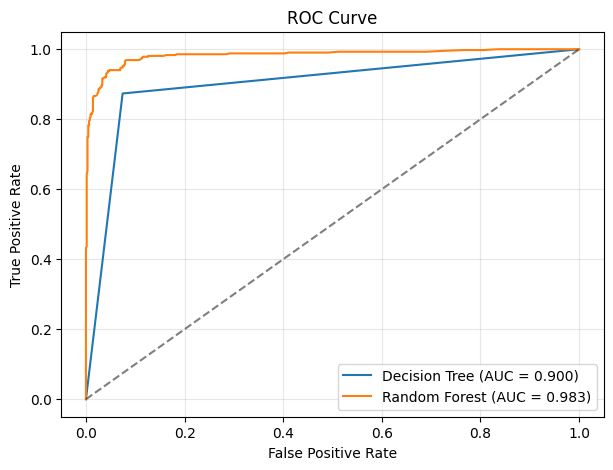

In [11]:

import matplotlib.pyplot as plt

from sklearn.metrics import (
    roc_curve,
    precision_recall_curve,
    roc_auc_score,
    average_precision_score
)

tree.fit(X_train, y_train)
rf.fit(X_train, y_train)

plt.figure(figsize=(7, 5))

for name, model in [("Decision Tree", tree), ("Random Forest", rf)]:
    probabilities = model.predict_proba(X_test)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, probabilities)
    auc = roc_auc_score(y_test, probabilities)

    plt.plot(fpr, tpr, label=f"{name} (AUC = {auc:.3f})")

plt.plot([0, 1], [0, 1], "k--", alpha=0.5)
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.legend()
plt.grid(alpha=0.3)
plt.show()


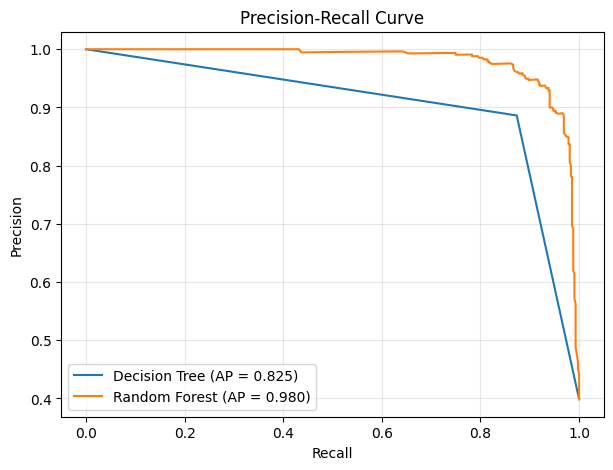

In [12]:

plt.figure(figsize=(7, 5))

for name, model in [("Decision Tree", tree), ("Random Forest", rf)]:
    probabilities = model.predict_proba(X_test)[:, 1]

    precision, recall, _ = precision_recall_curve(
        y_test, probabilities
    )

    ap = average_precision_score(y_test, probabilities)

    plt.plot(recall, precision, label=f"{name} (AP = {ap:.3f})")

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curve")
plt.legend()
plt.grid(alpha=0.3)
plt.show()


**Conclusion:** Random Forest performed better than Decision Tree on both evaluation curves. Random Forest achieved a ROC AUC of 0.983 and an Average Precison of 0.980, compared to 0.900 and 0.825 for Decision Tree. This shows that Random Forest is better at distinguishing spam from legitimate emails and maintains higher precison acroos different recall levels. 

## 2.2 Threshold Selection Using Out-of-Fold Predictons 

In [13]:

from sklearn.model_selection import cross_val_predict

oof = cross_val_predict(
    rf,
    X_train,
    y_train,
    cv=cv,
    method="predict_proba"
)[:, 1]

print("Number of OOF predictions:", len(oof))
print("Minimum probability:", round(oof.min(), 4))
print("Maximum probability:", round(oof.max(), 4))


Number of OOF predictions: 3153
Minimum probability: 0.0
Maximum probability: 1.0


In [14]:

fpr, tpr, thresholds = roc_curve(
    y_train, oof, drop_intermediate=False
)

valid_thresholds = np.where(fpr <= 0.01)[0]

best_recall = tpr[valid_thresholds].max()

candidates = valid_thresholds[
    tpr[valid_thresholds] == best_recall
]

best_idx = candidates[np.argmax(thresholds[candidates])]

t = thresholds[best_idx]

print(f"Selected threshold: {t:.6f}")
print(f"OOF FPR: {fpr[best_idx]:.6f}")
print(f"OOF Recall: {tpr[best_idx]:.6f}")


Selected threshold: 0.753333
OOF FPR: 0.009494
OOF Recall: 0.802705


**Threshold Selection:** The selected threshold is 0.753333. Using out-of-fold predictions, the false positive rate was 0.009494 (0.95%) and recall was 0.802705 (80.27%). The selected threshold satisfies the requirement of FPR ≤ 1% on the training out-of-fold predictions.

## 2.3 Test Evaluation at the Selected Threshold

In [15]:

from sklearn.metrics import (
    confusion_matrix,
    precision_score,
    recall_score
)

test_probabilities = rf.predict_proba(X_test)[:, 1]
test_predictions = (test_probabilities >= t).astype(int)

cm = confusion_matrix(y_test, test_predictions, labels=[0, 1])
tn, fp, fn, tp = cm.ravel()

precision = precision_score(y_test, test_predictions)
recall = recall_score(y_test, test_predictions)
test_fpr = fp / (fp + tn)

print("Confusion Matrix:")
print(pd.DataFrame(
    cm,
    index=["Actual Legitimate", "Actual Spam"],
    columns=["Predicted Legitimate", "Predicted Spam"]
))

print(f"\nPrecision: {precision:.4f}")
print(f"Recall: {recall:.4f}")
print(f"FPR: {test_fpr:.4f}")
print(f"Legitimate emails flagged: {fp} out of {fp + tn}")
print(f"1% target met: {test_fpr <= 0.01}")


Confusion Matrix:
                   Predicted Legitimate  Predicted Spam
Actual Legitimate                   627               5
Actual Spam                          83             336

Precision: 0.9853
Recall: 0.8019
FPR: 0.0079
Legitimate emails flagged: 5 out of 632
1% target met: True


**Conclusion:** The selected threshold of 0.753333 achieved a test precision of 0.9853, recall of 0.8019, and FPR of 0.0079. Only 5 out of 632 legitimate emails were incorrectly classified as spam. Therefore, the % falsen positive rate requirement was satisfied on the test set. 

## 2.4 Feature Importances

In [16]:

from sklearn.inspection import permutation_importance

perm = permutation_importance(
    rf,
    X_test,
    y_test,
    n_repeats=10,
    random_state=SEED,
    scoring="accuracy"
)

built_in = pd.DataFrame({
    "Feature": feature_names,
    "Importance": rf.feature_importances_
}).sort_values("Importance", ascending=False).head(5)

permutation = pd.DataFrame({
    "Feature": feature_names,
    "Importance": perm.importances_mean
}).sort_values("Importance", ascending=False).head(5)

print("Top 5 Built-in Feature Importances:")
display(built_in)

print("Top 5 Permutation Importances:")
display(permutation)


Top 5 Built-in Feature Importances:


,Feature,Importance
51,char_freq_exclam,0.111210
52,char_freq_dollar,0.093678
6,word_freq_remove,0.090194
54,capital_run_length_average,0.066163
20,word_freq_your,0.058858


Top 5 Permutation Importances:


,Feature,Importance
6,word_freq_remove,0.033302
51,char_freq_exclam,0.016365
24,word_freq_hp,0.014462
52,char_freq_dollar,0.010466
15,word_freq_free,0.009039


**Conclusion:** The two feature importance methods produced different rankings. For example, `word_freq_remove` ranked third in built-in importance (0.090194), but first in permutation importance (0.033302).

Built-in importance measures how much a feature reduces impurity during tree training. Permutation importance measures how much test accuracy decreases when the feature values are randomly shuffled.

Therefore, the rankings differ because the methods measure feature importance in different ways. The results suggest that `word_freq_remove` has a strong influence on the model's predictions on the test set.

# Part 3 — Voting
## 3.1 Hard Voting Function

In [17]:

def hard_vote(predictions, weights=None):
    """Weighted majority vote of several models' predicted labels, one label per sample."""
    predictions = np.asarray(predictions, dtype=int)

    n_models, n_samples = predictions.shape

    if weights is None:
        weights = np.ones(n_models)
    else:
        weights = np.asarray(weights, dtype=float)

    results = np.zeros(n_samples, dtype=int)

    for i in range(n_samples):
        counts = np.zeros(predictions.max() + 1)

        for m in range(n_models):
            label = predictions[m, i]
            counts[label] += weights[m]

        results[i] = np.argmax(counts)

    return results



In [18]:

print(hard_vote([[0, 1, 1], [0, 1, 0], [1, 1, 0]]))
print(hard_vote([[0, 1], [1, 0]]))
print(hard_vote([[0, 1], [1, 0]], weights=[1, 2]))
print(hard_vote([[2, 0], [2, 1], [0, 1]]))


[0 1 0]
[0 0]
[1 0]
[2 1]


## 3.2 Comparing Manual and Scikit-learn Hard Voting

In [19]:

from sklearn.ensemble import VotingClassifier
from sklearn.base import clone

member_predictions = []

for name, model in members:
    fitted_model = clone(model)
    fitted_model.fit(X_train, y_train)
    member_predictions.append(fitted_model.predict(X_test))

member_predictions = np.array(member_predictions)

manual_predictions = hard_vote(member_predictions)

voting_hard = VotingClassifier(
    estimators=members,
    voting="hard"
)

voting_hard.fit(X_train, y_train)

sklearn_predictions = voting_hard.predict(X_test)

agreement = np.mean(
    manual_predictions == sklearn_predictions
)

print("Predictions shape:", member_predictions.shape)
print(f"Agreement: {agreement:.4f}")
print(f"Agreement percentage: {agreement * 100:.2f}%")


Predictions shape: (3, 1051)
Agreement: 1.0000
Agreement percentage: 100.00%


**Concusion:** The manual hard voting implementation produced exactly the same predictions as sxikit-learn's VotingClassifier. The agreement was 1.0000 (100%) across all 1051 test samples. This confirms that our hard voting function works correctly fot the three classifiers. 

## 3.3 Disagreement Between Models

In [20]:

from itertools import combinations

member_names = [name for name, model in members]

disagreement_results = []

for i, j in combinations(range(len(members)), 2):
    disagreement = np.mean(
        member_predictions[i] != member_predictions[j]
    )

    disagreement_results.append({
        "Model Pair": f"{member_names[i]} vs {member_names[j]}",
        "Disagreement": disagreement
    })

disagreement_table = pd.DataFrame(disagreement_results)

display(disagreement_table.round(4))


,Model Pair,Disagreement
0,lr vs knn,0.0514
1,lr vs tree,0.1018
2,knn vs tree,0.1056


**Conclusion:** Logistic Regression and KNN had the lowest disagreement rate (0.0514), while KNN and Decision Tree had the highest (0.1056). This shows that Decision Tree makes different predictions more often than the other models. Model diversity can help a voting ensemble because different models may make different errors. 

## 3.4 Cross-Validation: Hard vs Soft Voting

In [21]:

voting_soft = VotingClassifier(
    estimators=members,
    voting="soft"
)

voting_models = {
    "lr": lr,
    "knn": knn,
    "tree": tree,
    "hard": voting_hard,
    "soft": voting_soft
}

voting_scores = {}

for name, model in voting_models.items():
    scores = cross_validate(
        model,
        X_train,
        y_train,
        cv=cv,
        scoring="accuracy"
    )["test_score"]

    voting_scores[name] = scores

voting_table = pd.DataFrame(
    voting_scores,
    index=[f"Fold {i}" for i in range(1, 6)]
).T

voting_table["Mean"] = voting_table.iloc[:, :5].mean(axis=1)
voting_table["Std"] = voting_table.iloc[:, :5].std(axis=1, ddof=0)

display(voting_table.round(4))


,Fold 1,Fold 2,Fold 3,Fold 4,Fold 5,Mean,Std
lr,0.9176,0.9525,0.9414,0.9508,0.9286,0.9382,0.0133
knn,0.9017,0.9303,0.9017,0.9095,0.9079,0.9102,0.0105
tree,0.8938,0.9113,0.8970,0.8937,0.8889,0.8969,0.0076
hard,0.9192,0.9509,0.9334,0.9460,0.9190,0.9337,0.0132
soft,0.9192,0.9461,0.9398,0.9429,0.9190,0.9334,0.0118


In [22]:

member_names = ["lr", "knn", "tree"]

best_member = max(
    member_names,
    key=lambda name: voting_scores[name].mean()
)

hard_diff = voting_scores["hard"] - voting_scores[best_member]
soft_diff = voting_scores["soft"] - voting_scores[best_member]

diff_table = pd.DataFrame(
    [hard_diff, soft_diff],
    index=[
        "Hard - Best Member",
        "Soft - Best Member"
    ],
    columns=[f"Fold {i}" for i in range(1, 6)]
)

diff_table["Mean"] = diff_table.iloc[:, :5].mean(axis=1)
diff_table["Std"] = diff_table.iloc[:, :5].std(axis=1, ddof=0)

print("Best member:", best_member)
display(diff_table.round(4))


Best member: lr


,Fold 1,Fold 2,Fold 3,Fold 4,Fold 5,Mean,Std
Hard - Best Member,0.0016,-0.0016,-0.0079,-0.0048,-0.0095,-0.0044,0.0041
Soft - Best Member,0.0016,-0.0063,-0.0016,-0.0079,-0.0095,-0.0048,0.0041


**Conclusion:** Logistic Regression was the best individual model, with a mean cross-validation accuracy of 0.9382. Hard Voting achieved 0.9337, while Soft Voting achieved 0.9334.

The mean paired difference between Hard Voting and Logistic Regression was -0.0044, with a standard deviation of 0.0041. For Soft Voting, the mean difference was -0.0048, with the same standard deviation of 0.0041.

In both cases, the absolute mean difference was slightly larger than the standard deviation. Therefore, according to the assignment's comparison rule, neither voting method outperformed the best individual model. Combining multiple models did not improve cross-validation accuracy in this experiment.

# Part 4 — Stacking
## 4.1 Out-of-Fold Stacking by Hand

In [23]:

meta_features = np.column_stack([
    cross_val_predict(
        model,
        X_train,
        y_train,
        cv=cv,
        method="predict_proba"
    )[:, 1]
    for name, model in members
])

print("Meta-features shape:", meta_features.shape)
print("First 5 rows:")
print(np.round(meta_features[:5], 4))


Meta-features shape: (3153, 3)
First 5 rows:
[[0.9996 1.     1.    ]
 [0.8545 1.     1.    ]
 [0.     0.     0.    ]
 [0.0267 0.     0.    ]
 [0.     0.     0.    ]]


In [24]:

meta_model = LogisticRegression()
meta_model.fit(meta_features, y_train)

test_meta_features = np.column_stack([
    clone(model)
    .fit(X_train, y_train)
    .predict_proba(X_test)[:, 1]
    for name, model in members
])

manual_stack_predictions = meta_model.predict(test_meta_features)
manual_stack_accuracy = np.mean(
    manual_stack_predictions == y_test
)

print("Test meta-features shape:", test_meta_features.shape)
print("Meta-learner coefficients:", meta_model.coef_)
print(f"Manual stacking accuracy: {manual_stack_accuracy:.4f}")


Test meta-features shape: (1051, 3)
Meta-learner coefficients: [[4.37902927 2.42021838 1.22806505]]
Manual stacking accuracy: 0.9429


In [25]:

from sklearn.ensemble import StackingClassifier

stack = StackingClassifier(
    estimators=members,
    final_estimator=LogisticRegression(),
    cv=cv
)

stack.fit(X_train, y_train)

sklearn_stack_predictions = stack.predict(X_test)
sklearn_stack_accuracy = stack.score(X_test, y_test)

coef_difference = np.max(
    np.abs(meta_model.coef_ - stack.final_estimator_.coef_)
)

predictions_identical = np.array_equal(
    manual_stack_predictions,
    sklearn_stack_predictions
)

print(f"Maximum coefficient difference: {coef_difference:.8f}")
print(f"Predictions identical: {predictions_identical}")
print(f"Manual stacking accuracy: {manual_stack_accuracy:.4f}")
print(f"Sklearn stacking accuracy: {sklearn_stack_accuracy:.4f}")


Maximum coefficient difference: 0.00000000
Predictions identical: True
Manual stacking accuracy: 0.9429
Sklearn stacking accuracy: 0.9429


## 4.2 Naive Stacking vs Out-of-Fold Stacking

In [26]:

naive_meta_features = np.column_stack([
    clone(model)
    .fit(X_train, y_train)
    .predict_proba(X_train)[:, 1]
    for name, model in members
])

naive_meta_model = LogisticRegression()
naive_meta_model.fit(naive_meta_features, y_train)

coefficient_table = pd.DataFrame({
    "Model": [name for name, model in members],
    "Naive": naive_meta_model.coef_[0],
    "Out-of-Fold": meta_model.coef_[0]
})

display(coefficient_table.round(4))


,Model,Naive,Out-of-Fold
0,lr,1.9452,4.3790
1,knn,1.8048,2.4202
2,tree,8.2973,1.2281


**Conclusion:** The Decision Tree coefficient was much higher in Naive Stacking (8.2973) than in Out-of-Fold Stacking (1.2281). This happens because the tree can memorize training examples, making its predictions on the same training data overly optimistic.

In Out-of-Fold Stacking, each prediction comes from a model that did not train on that sample. This reduces data leakage and helps the meta-learner estimate how useful each model is on unseen data.

## 4.3 Cross-Validation Comparison

In [27]:

stacking_models = {
    "stack": stack,
    "soft": voting_soft,
    "best_member": dict(members)[best_member]
}

stacking_scores = {}

for name, model in stacking_models.items():
    scores = cross_validate(
        model,
        X_train,
        y_train,
        cv=cv,
        scoring="accuracy"
    )["test_score"]

    stacking_scores[name] = scores

stacking_table = pd.DataFrame(
    stacking_scores,
    index=[f"Fold {i}" for i in range(1, 6)]
).T

stacking_table["Mean"] = stacking_table.iloc[:, :5].mean(axis=1)
stacking_table["Std"] = stacking_table.iloc[:, :5].std(axis=1, ddof=0)

display(stacking_table.round(4))


,Fold 1,Fold 2,Fold 3,Fold 4,Fold 5,Mean,Std
stack,0.9239,0.9540,0.9461,0.9524,0.9238,0.9401,0.0135
soft,0.9192,0.9461,0.9398,0.9429,0.9190,0.9334,0.0118
best_member,0.9176,0.9525,0.9414,0.9508,0.9286,0.9382,0.0133


In [28]:

stack_vs_best = (
    stacking_scores["stack"] - stacking_scores["best_member"]
)

stack_vs_soft = (
    stacking_scores["stack"] - stacking_scores["soft"]
)

stack_diff_table = pd.DataFrame(
    [stack_vs_best, stack_vs_soft],
    index=["Stack - Best Member", "Stack - Soft Voting"],
    columns=[f"Fold {i}" for i in range(1, 6)]
)

stack_diff_table["Mean"] = stack_diff_table.iloc[:, :5].mean(axis=1)
stack_diff_table["Std"] = stack_diff_table.iloc[:, :5].std(axis=1, ddof=0)

display(stack_diff_table.round(4))


,Fold 1,Fold 2,Fold 3,Fold 4,Fold 5,Mean,Std
Stack - Best Member,0.0063,0.0016,0.0048,0.0016,-0.0048,0.0019,0.0038
Stack - Soft Voting,0.0048,0.0079,0.0063,0.0095,0.0048,0.0067,0.0019


**Conclusion:** Stacking achieved the highest mean cross-validation accuracy of 0.9401, compared to 0.9382 for the best individual model (Logistic Regression) and 0.9334 for Soft Voting.

The mean paired difference between Stacking and Logistic Regression was 0.0019, with a standard deviation of 0.0038. Since the mean difference was smaller than its standard deviation, there was no clear winner according to the assignment rule.

Compared to Soft Voting, Stacking had a mean paired improvement of 0.0067 with a standard deviation of 0.0019. This indicates that Stacking performed better than Soft Voting in this experiment.

Overall, Stacking improved the combination of model predictions, but its advantage over the best individual model was too small to establish a clear winner.

# Part 5 — AdaBoost and Label Noise
## 5.1 Implementing One AdaBoost Round

In [29]:

import math

def adaboost_step(y_true, y_pred, weights):
    """One AdaBoost round: return alpha and updated sample weights."""
    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred)
    weights = np.asarray(weights, dtype=float)

    wrong = (y_true != y_pred)
    error = weights[wrong].sum() / weights.sum()

    if error == 0:
        return math.inf, weights / weights.sum()

    alpha = math.log((1 - error) / error)

    new_weights = weights.copy()
    new_weights[wrong] *= math.exp(alpha)
    new_weights /= new_weights.sum()

    return float(alpha), new_weights


In [30]:

alpha, new_weights = adaboost_step(
    [1, 1, 0, 0],
    [1, 0, 0, 0],
    [1, 1, 1, 1]
)

print(f"Alpha: {alpha:.4f}")
print("New weights:", np.round(new_weights, 4))
print("Sum:", new_weights.sum())


Alpha: 1.0986
New weights: [0.1667 0.5    0.1667 0.1667]
Sum: 1.0


In [31]:

tests = [
    ([1, 1, 1, 0], [0, 0, 0, 0], [1, 1, 1, 1]),
    ([1, 0], [0, 0], [1, 1]),
    ([1, 0, 1], [1, 0, 1], [2, 2, 4]),
    ([-1, 1, 1, -1], [-1, 1, -1, -1], [0.1, 0.2, 0.1, 0.1])
]

for i, (y_true, y_pred, weights) in enumerate(tests, 2):
    alpha, new_weights = adaboost_step(
        y_true, y_pred, weights
    )

    print(f"Test {i}:")
    print(f"  Alpha: {alpha:.4f}")
    print(f"  Weights: {np.round(new_weights, 4)}")


Test 2:
  Alpha: -1.0986
  Weights: [0.1667 0.1667 0.1667 0.5   ]
Test 3:
  Alpha: 0.0000
  Weights: [0.5 0.5]
Test 4:
  Alpha: inf
  Weights: [0.25 0.25 0.5 ]
Test 5:
  Alpha: 1.3863
  Weights: [0.125 0.25  0.5   0.125]


## 5.2 Three AdaBoost Rounds from the Lecture

In [32]:

x = np.arange(1, 11)

y_toy = np.array([1, 1, 1, 0, 0, 0, 1, 1, 1, 0])

stump_1 = np.where(x <= 3.5, 1, 0)
stump_2 = np.where(x <= 9.5, 1, 0)
stump_3 = np.where(x <= 6.5, 0, 1)

stumps = [stump_1, stump_2, stump_3]

w = np.full(10, 0.1)

for round_num, predictions in enumerate(stumps, 1):
    error = w[predictions != y_toy].sum() / w.sum()

    alpha, w = adaboost_step(y_toy, predictions, w)

    print(f"Round {round_num}")
    print(f"Error: {error:.4f}")
    print(f"Alpha: {alpha:.4f}")
    print("Weights:", np.round(w, 4))
    print()


Round 1
Error: 0.3000
Alpha: 0.8473
Weights: [0.0714 0.0714 0.0714 0.0714 0.0714 0.0714 0.1667 0.1667 0.1667 0.0714]

Round 2
Error: 0.2143
Alpha: 1.2993
Weights: [0.0455 0.0455 0.0455 0.1667 0.1667 0.1667 0.1061 0.1061 0.1061 0.0455]

Round 3
Error: 0.1818
Alpha: 1.5041
Weights: [0.125  0.125  0.125  0.1019 0.1019 0.1019 0.0648 0.0648 0.0648 0.125 ]



**Conclusion:** The three AdaBoost rounds produced weighted errors of 0.3000, 0.2143, and 0.1818, with alpha values of 0.8473, 1.2993, and 1.5041. After each round, the weights were updated to give more attention to misclassified samples. The first round matched the lecture example, and the calculations followed the required AdaBoost update formula.

## 5.3 Comparing Manual AdaBoost with Scikit-learn

In [33]:

ada.fit(X_train, y_train)

w = np.full(len(y_train), 1 / len(y_train))

alpha_differences = []
error_differences = []

for i in range(5):
    stump = ada.estimators_[i]
    predictions = stump.predict(X_train)

    error = w[predictions != y_train].sum() / w.sum()
    alpha, w = adaboost_step(y_train, predictions, w)

    sklearn_alpha = ada.estimator_weights_[i]
    sklearn_error = ada.estimator_errors_[i]

    alpha_differences.append(abs(alpha - sklearn_alpha))
    error_differences.append(abs(error - sklearn_error))

    print(
        f"Round {i + 1}: "
        f"Manual error={error:.6f}, "
        f"Sklearn error={sklearn_error:.6f}, "
        f"Manual alpha={alpha:.6f}, "
        f"Sklearn alpha={sklearn_alpha:.6f}"
    )

print()
print(f"Maximum alpha difference: {max(alpha_differences):.10f}")
print(f"Maximum error difference: {max(error_differences):.10f}")


Round 1: Manual error=0.210276, Sklearn error=0.210276, Manual alpha=1.323263, Sklearn alpha=1.323263
Round 2: Manual error=0.240820, Sklearn error=0.240820, Manual alpha=1.148188, Sklearn alpha=1.148188
Round 3: Manual error=0.277794, Sklearn error=0.277794, Manual alpha=0.955429, Sklearn alpha=0.955429
Round 4: Manual error=0.276771, Sklearn error=0.276771, Manual alpha=0.960535, Sklearn alpha=0.960535
Round 5: Manual error=0.348862, Sklearn error=0.348862, Manual alpha=0.624044, Sklearn alpha=0.624044

Maximum alpha difference: 0.0000000000
Maximum error difference: 0.0000000000


**Conclusion:** The manual AdaBoost implementation matched scikit-learn for the first five rounds. The maximum absolute differences for both alpha and weighted error were 0.0000000000. This confirms that our function correctly calculates the weighted error, alpha, and sample weight updates.

## 5.4 Training and Test Error by Round

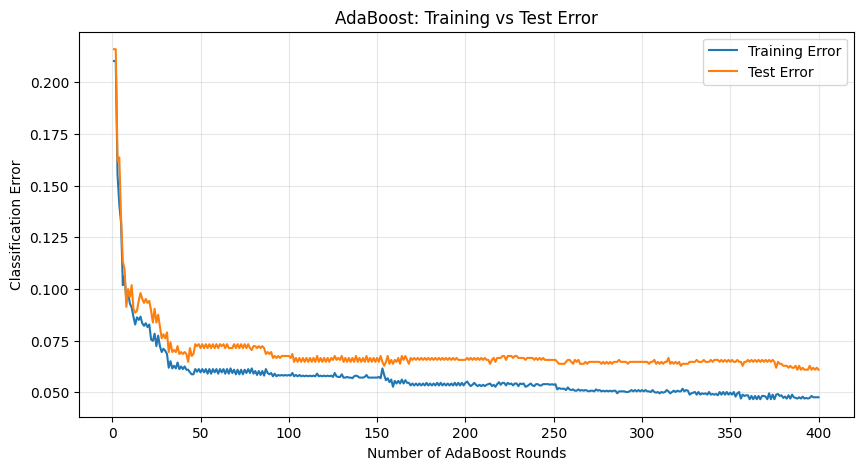

Number of rounds: 400
Training error at round 400: 0.0476
Test error at round 400: 0.0609


In [34]:

train_accuracy = np.array(
    list(ada.staged_score(X_train, y_train))
)

test_accuracy_by_round = np.array(
    list(ada.staged_score(X_test, y_test))
)

train_error = 1 - train_accuracy
test_error = 1 - test_accuracy_by_round

rounds = np.arange(1, len(train_error) + 1)

plt.figure(figsize=(10, 5))

plt.plot(rounds, train_error, label="Training Error")
plt.plot(rounds, test_error, label="Test Error")

plt.xlabel("Number of AdaBoost Rounds")
plt.ylabel("Classification Error")
plt.title("AdaBoost: Training vs Test Error")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

print("Number of rounds:", len(rounds))
print(f"Training error at round 400: {train_error[-1]:.4f}")
print(f"Test error at round 400: {test_error[-1]:.4f}")


## 5.5 Selecting the Best Number of Rounds with Cross-Validation

In [35]:

from sklearn.base import clone

cv_accuracy_curves = []

for fold_num, (train_idx, val_idx) in enumerate(
    cv.split(X_train, y_train), 1
):
    ada_fold = clone(ada)

    ada_fold.fit(
        X_train[train_idx],
        y_train[train_idx]
    )

    val_accuracy = list(
        ada_fold.staged_score(
            X_train[val_idx],
            y_train[val_idx]
        )
    )

    cv_accuracy_curves.append(val_accuracy)

    print(f"Fold {fold_num} completed")

cv_accuracy_curves = np.array(cv_accuracy_curves)

mean_cv_accuracy = cv_accuracy_curves.mean(axis=0)

best_round = np.argmax(mean_cv_accuracy) + 1

print()
print("Best round selected by CV:", best_round)
print(f"Best mean CV accuracy: {mean_cv_accuracy[best_round - 1]:.4f}")


Fold 1 completed
Fold 2 completed
Fold 3 completed
Fold 4 completed
Fold 5 completed

Best round selected by CV: 362
Best mean CV accuracy: 0.9429


## 5.6 Comparing CV-Selected and Test-Best Rounds

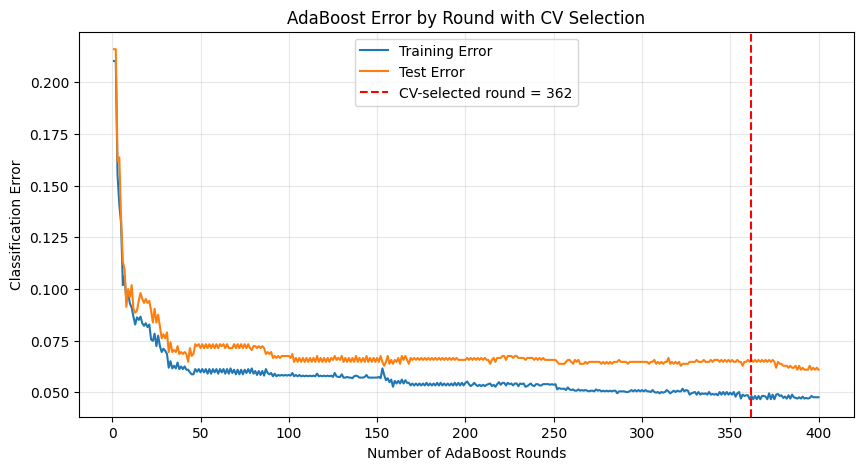

CV-selected round: 362
Test error at CV-selected round: 0.0657
Best round on test curve: 388
Lowest test error: 0.0609
Test standard error: 0.0076
Difference in test errors: 0.0048
Difference exceeds standard error: False


In [36]:

best_test_round = np.argmin(test_error) + 1

cv_selected_test_error = test_error[best_round - 1]
best_test_error = test_error[best_test_round - 1]

n_test = len(y_test)
p = 1 - cv_selected_test_error

standard_error = np.sqrt(p * (1 - p) / n_test)
error_difference = abs(cv_selected_test_error - best_test_error)

plt.figure(figsize=(10, 5))

plt.plot(rounds, train_error, label="Training Error")
plt.plot(rounds, test_error, label="Test Error")

plt.axvline(
    best_round,
    color="red",
    linestyle="--",
    label=f"CV-selected round = {best_round}"
)

plt.xlabel("Number of AdaBoost Rounds")
plt.ylabel("Classification Error")
plt.title("AdaBoost Error by Round with CV Selection")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

print("CV-selected round:", best_round)
print(f"Test error at CV-selected round: {cv_selected_test_error:.4f}")

print("Best round on test curve:", best_test_round)
print(f"Lowest test error: {best_test_error:.4f}")

print(f"Test standard error: {standard_error:.4f}")
print(f"Difference in test errors: {error_difference:.4f}")
print("Difference exceeds standard error:", error_difference > standard_error)


**Conclusion:** Five-fold cross-validation selected 362 AdaBoost rounds, with a mean validation accuracy of 0.9429. The test error at this round was 0.0657. The lowest test error was 0.0609 at round 388, but the difference of 0.0048 was smaller than the test standard error of 0.0076. Therefore, the difference does not provide strong evidence that the test-best round is better. The number of rounds was selected using training data only.

## 5.7 Label Noise Experiment

In [37]:

def flip_labels(y, rate, seed):
    rng = np.random.default_rng(seed)
    idx = rng.choice(
        len(y),
        size=round(rate * len(y)),
        replace=False
    )

    y_noisy = y.copy()
    y_noisy[idx] = 1 - y_noisy[idx]

    return y_noisy, idx


y_noisy, flipped_idx = flip_labels(
    y_train, 0.20, SEED
)

print("Total training samples:", len(y_train))
print("Flipped labels:", len(flipped_idx))
print("Actual noise rate:", len(flipped_idx) / len(y_train))
print("Test labels remain unchanged:", len(y_test))


Total training samples: 3153
Flipped labels: 631
Actual noise rate: 0.2001268633047891
Test labels remain unchanged: 1051


## 5.8 Comparing Models with 0% and 20% Label Noise

In [38]:

from sklearn.metrics import accuracy_score

ada200 = AdaBoostClassifier(
    n_estimators=200,
    random_state=SEED
)

noise_models = {
    "Decision Tree": tree,
    "Random Forest": rf,
    "AdaBoost": ada200
}

clean_accuracies = {}
noisy_accuracies = {name: [] for name in noise_models}

# Train each model on clean labels
for name, model in noise_models.items():
    fitted_model = clone(model)
    fitted_model.fit(X_train, y_train)

    clean_accuracies[name] = fitted_model.score(X_test, y_test)

# Repeat the 20% label noise experiment five times
for r in range(5):
    y_noisy, idx = flip_labels(y_train, 0.20, SEED + r)

    for name, model in noise_models.items():
        fitted_model = clone(model)
        fitted_model.fit(X_train, y_noisy)

        accuracy = fitted_model.score(X_test, y_test)
        noisy_accuracies[name].append(accuracy)

    print(f"Draw {r + 1} completed")

# Summarize results
noise_results = []

for name in noise_models:
    clean_acc = clean_accuracies[name]
    noisy_acc = np.array(noisy_accuracies[name])
    losses = clean_acc - noisy_acc

    noise_results.append({
        "Model": name,
        "Clean Accuracy": clean_acc,
        "Noisy Mean": noisy_acc.mean(),
        "Noisy Std": noisy_acc.std(),
        "Loss Mean": losses.mean(),
        "Loss Std": losses.std(),
        "Five Losses": np.round(losses, 4).tolist()
    })

noise_df = pd.DataFrame(noise_results)
display(noise_df.round(4))



Draw 1 completed
Draw 2 completed
Draw 3 completed
Draw 4 completed
Draw 5 completed


,Model,Clean Accuracy,Noisy Mean,Noisy Std,Loss Mean,Loss Std,Five Losses
0,Decision Tree,0.9049,0.7410,0.0228,0.1638,0.0228,"[0.1627, 0.1703, 0.1618, 0.1265, 0.1979]"
1,Random Forest,0.9448,0.9005,0.0068,0.0443,0.0068,"[0.0466, 0.0457, 0.0466, 0.0314, 0.0514]"
2,AdaBoost,0.9343,0.9085,0.0058,0.0259,0.0058,"[0.0343, 0.0266, 0.0295, 0.0181, 0.0209]"


## 5.9 Final AdaBoost Weights on Flipped Labels

In [39]:

weight_shares = []

for r in range(5):
    y_noisy, idx = flip_labels(y_train, 0.20, SEED + r)

    model = clone(ada200)
    model.fit(X_train, y_noisy)

    w = np.full(len(y_train), 1 / len(y_train))

    initial_share = w[idx].sum()

    for stump in model.estimators_:
        predictions = stump.predict(X_train)
        alpha, w = adaboost_step(y_noisy, predictions, w)

    final_share = w[idx].sum()
    weight_shares.append(final_share)

    print(
        f"Draw {r + 1}: "
        f"Initial share={initial_share:.4f}, "
        f"Final share={final_share:.4f}"
    )

weight_shares = np.array(weight_shares)

print()
print(f"Initial weight share: {initial_share:.4f}")
print(f"Final weight share mean: {weight_shares.mean():.4f}")
print(f"Final weight share std: {weight_shares.std():.4f}")


Draw 1: Initial share=0.2001, Final share=0.3933
Draw 2: Initial share=0.2001, Final share=0.3949
Draw 3: Initial share=0.2001, Final share=0.4032
Draw 4: Initial share=0.2001, Final share=0.3953
Draw 5: Initial share=0.2001, Final share=0.3893

Initial weight share: 0.2001
Final weight share mean: 0.3952
Final weight share std: 0.0045


### Part 5 - Final Conclusion
The manual AdaBoost implementation matched the lecture example and scikit-learn, with maximum differences of 0.0000000000 for both alpha and weighted error.

Five-fold-cross-validation selectee 362 rounds with a mean accuracy of 0.9429. The test error at this round was 0.0657, while the lowest test error was 0.0609 at round 388. The difference (0.0048) was smaller than the test standard error (0.0076), so there was no clear advantage tousing the test-best round. 

With 20% label noise, Decision Tree lost the most accuracy (0.1638 ± 0.0228), followed by Random Forest (0.0443 ± 0.0068) and AdaBoost (0.0259 ± 0.0058). Decision Tree was most sensitive because it could fit incorrect training labels, while Random Forest reduced their influence by averaging many trees. AdaBoost had the smallest loss in this experiment, although it increased the total weight on flipped labels from 0.2001 to 0.3952 ± 0.0045. 

The paired losses showed the same ordering across all five draws, with differences larger than their observed variation. Therefore, AdaBoost was the most robust model to label noise in this experiment, while Decision Tree was the least robust.

# Part 6 — Recommendation and Reproducibility
## 6.1 Final Model Recommendation

I recommend Random Forest for the spam filter because it achieved the highest mean cross-validation accuracy of 0.9461 and a test accuracy of 0.9448. Using the threshold of 0.753333 selected from out-of-fold training predictions, the model achieved a false positive rate of 0.0079, precision of 0.9853, and recall of 0.8019 on the test set. Only 5 out of 632 legitimate emails were incorrectly classified as spam, meeting the 1% false positive target. Random Forest also showed relatively good robustness to label noise, losing 0.0443 accuracy compared with 0.1638 for a single Decision Tree. Although stacking achieved a higher mean accuracy than soft voting, its advantage over the best individual member was smaller than the variation across folds, so there was no clear winner. Therefore, Random Forest provides a strong balance between accuracy, reliability, and control over false positives.